# Intervention further analysis: MuSiQue vs synthetic questions

Three questions about the full study (Instructor Review #7 asks for every causal result split by source):
1. Do targeted edits work better on MuSiQue (real entities) than on synthetic questions (fictional)?
2. Do SAE features add causal value over raw activations?
3. Do Critic refusals explain the difference?

- **Exploratory:** the split wasn't pre-registered. It qualifies Table P; it doesn't replace it.
- **Deterministic:** saved files only, no Claude or API calls, fixed seeds. Table P is recomputed and checked first.
- **Terms:** a **flip** is a label opposite to the stored one. **Δ** = targeted − random flip rate (pp), paired by
  episode. CIs are 95%.

The takeaways describe run `20261106T000808809026Z-02871d677287`.

## Choose the run

Figures are saved as SVG to the run's `merge/figures/further_analysis/`.

In [1]:
RUN_DIR = "results/intervention_layer25/20261106T000808809026Z-02871d677287"

In [2]:
import json
import os
from pathlib import Path
from types import SimpleNamespace

# Find the repo root so the notebook works from notebooks/intervention/.
ROOT = Path.cwd()
while not (ROOT / "configs" / "intervention").is_dir():
    if ROOT.parent == ROOT:
        raise RuntimeError("Run this notebook from inside the repository.")
    ROOT = ROOT.parent
os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D
from IPython.display import display

from mas_sae.evaluation.behavior_labels import V020_CANDIDATE, classify_candidate
from mas_sae.experiments.artifacts import sha256_file
from mas_sae.intervention.analysis import stats
from mas_sae.intervention.analysis.tables import Outcomes, ci_text
from mas_sae.intervention.experiment.conditions import Condition
from mas_sae.intervention.experiment.episodes import OPPOSITE
from mas_sae.intervention.generation.edits import ARMS

MERGE_DIR = Path(RUN_DIR) / "merge"
FIGURE_DIR = MERGE_DIR / "figures" / "further_analysis"
if not (MERGE_DIR / "summary.json").is_file():
    raise FileNotFoundError(f"{MERGE_DIR / 'summary.json'} not found: run the merge stage for this run first.")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

## Load and check

Reads the run's labeled rows and frozen config, plus the stored episodes file for A1/C1 text. That file isn't
in git and is refused unless its sha256 matches. Table P must reproduce exactly.

In [3]:
INPUT_FILES = {"summary": MERGE_DIR / "summary.json", "frozen run": Path(RUN_DIR) / "frozen_run.json",
               "labeled rows": MERGE_DIR / "labeled_rows.jsonl", "Table P": MERGE_DIR / "table_P_primary.csv"}
input_hashes = {name: sha256_file(path) for name, path in INPUT_FILES.items()}  # taken before anything is read

summary = json.loads(INPUT_FILES["summary"].read_text())
if summary.get("labels_stubbed"):
    raise RuntimeError("This run's labels are stubbed (smoke run): its numbers are meaningless.")
frozen_run = json.loads(INPUT_FILES["frozen run"].read_text())
config = frozen_run["config"]
with open(INPUT_FILES["labeled rows"]) as f:
    labeled_rows = [json.loads(line) for line in f]
row_keys = [(row["episode_id"], row["condition"]) for row in labeled_rows]
if len(set(row_keys)) != len(row_keys):
    raise ValueError("labeled_rows.jsonl repeats an (episode, condition) pair.")

analysis_plan = SimpleNamespace(**summary["analysis_plan"])
EDIT_SIZE = summary["edit_size"]
N_RANDOM_DRAWS = config["experiment"]["number_of_random_draws"]
PRIMARY_SAES = list(analysis_plan.primary_representations)
CONTROLS = [name for name, rep in config["representations"].items() if rep["role"] == "control"]
if len(CONTROLS) != 1:
    raise ValueError(f"Expected one control representation (raw activations), found {CONTROLS}.")
RAW = CONTROLS[0]
REPRESENTATIONS = PRIMARY_SAES + [RAW]  # figure order: the pre-specified SAEs, then the raw-activation control
SPLICED_SAES = [name for name, rep in config["representations"].items() if rep["kind"] != "activations"]

outcomes = Outcomes(labeled_rows, EDIT_SIZE, N_RANDOM_DRAWS, analysis_plan)
episodes = outcomes.episodes()
edit_rows = [row for row in labeled_rows if row["kind"] == "edit"]

# Analysed and excluded episodes must split the frozen study list exactly.
frozen_ids, excluded_ids = frozen_run["episode_ids"], set(summary["excluded_episodes"])
if (len(set(frozen_ids)) != len(frozen_ids) or set(episodes) & excluded_ids
        or set(episodes) | excluded_ids != set(frozen_ids)):
    raise ValueError("Analysed + excluded episodes don't match the frozen study list.")

print(f"{len(episodes)} episodes analysed, {len(summary['excluded_episodes'])} excluded, "
      f"{len(labeled_rows):,} labeled answers; r = {EDIT_SIZE}, {N_RANDOM_DRAWS} random draws per condition.")

983 episodes analysed, 17 excluded, 63,895 labeled answers; r = 0.2, 3 random draws per condition.


In [4]:
INPUT_FILES["labeling settings"] = Path(config["inputs"]["stored_labels"]) / "run_settings.json"
INPUT_FILES["stored episodes"] = Path(config["inputs"]["interactions"])
if not INPUT_FILES["stored episodes"].is_file():
    raise FileNotFoundError(f"{INPUT_FILES['stored episodes']} not found. It is the collection's stored episodes "
                            "file, which isn't in git: copy it to this path from the machine that ran the study.")
for name in ("labeling settings", "stored episodes"):
    input_hashes[name] = sha256_file(INPUT_FILES[name])  # before reading
labeling_settings = json.loads(INPUT_FILES["labeling settings"].read_text())
if input_hashes["stored episodes"] != labeling_settings["episodes_sha256"]:
    raise ValueError(f"{INPUT_FILES['stored episodes']} isn't the file the stored labels were made from (sha256 differs).")
study = set(episodes)
with INPUT_FILES["stored episodes"].open() as f:
    stored_rows = [row for row in map(json.loads, f) if row["episode_id"] in study]
stored_episodes = {row["episode_id"]: row for row in stored_rows}
if len(stored_episodes) != len(stored_rows):
    raise ValueError(f"{INPUT_FILES['stored episodes']} repeats an analysed episode id.")
if len(stored_episodes) != len(study):
    raise ValueError(f"{len(study) - len(stored_episodes)} analysed episodes are missing from {INPUT_FILES['stored episodes']}.")

SOURCES = ["musique", "synthetic"]
SOURCE_NAME = {"musique": "MuSiQue", "synthetic": "Synthetic"}
CONFIDENT = 0.999  # the full-study notebook's top bin: baseline first answer token has probability ≥ 0.999

# One row per analysed episode, in the order of outcomes.episodes(), so arrays from `outcomes` line up with it.
episode_facts = pd.DataFrame({
    "source": [stored_episodes[e]["dataset_source"] for e in episodes],
    "stratum": [outcomes.stratum[e] for e in episodes],
    "hops": [int(stored_episodes[e]["hop_group"][0]) for e in episodes],
    "first_token_probability": [float(np.exp(outcomes.rows[(e, "baseline")]["first_token_logprob"])) for e in episodes],
    # What the Critic gave, by the project's rule-based labeler (text rules, no model):
    # answer, refusal, premise_rejection or unresolved.
    "critic_feedback_type": [classify_candidate(stored_episodes[e], V020_CANDIDATE)["feedback_type"] for e in episodes],
}, index=pd.Index(episodes, name="episode_id"))
if (episode_facts.source != [e.split(":")[0] for e in episodes]).any():
    raise ValueError("dataset_source disagrees with the episode id prefix.")
episode_facts["confident"] = episode_facts.first_token_probability >= CONFIDENT
episode_facts["critic_gave_answer"] = episode_facts.critic_feedback_type == "answer"
episode_facts["two_hop"] = episode_facts.hops == 2
is_musique = (episode_facts.source == "musique").to_numpy()
episodes_by_source = {source: list(episode_facts.index[episode_facts.source == source]) for source in SOURCES}
print({SOURCE_NAME[source]: len(ids) for source, ids in episodes_by_source.items()})

{'MuSiQue': 371, 'Synthetic': 612}


In [5]:
def is_flip(row: dict) -> bool:
    return row["label"] == OPPOSITE[row["stored_label"]]


def condition_values(representation: str, arm: str, source: str, episode_ids: list[str], value) -> np.ndarray:
    """Per episode, value(row) of the targeted edit, or its mean over the random draws (as the pipeline does)."""
    draws = [None] if source == "targeted" else range(N_RANDOM_DRAWS)
    per_draw = [[value(outcomes.rows[(e, Condition("edit", representation, arm, source, draw, EDIT_SIZE).key)])
                 for e in episode_ids] for draw in draws]
    return np.mean(np.array(per_draw, float), axis=0)


# The helper must count flips exactly as the pipeline does...
for representation in REPRESENTATIONS:
    for arm in ARMS:
        assert np.array_equal(condition_values(representation, arm, "targeted", episodes, is_flip),
                              outcomes.targeted(representation, arm, episodes))
        assert np.allclose(condition_values(representation, arm, "random", episodes, is_flip),
                           outcomes.random(representation, arm, episodes))

# ...the pipeline's code must reproduce the saved Table P...
table_p = pd.read_csv(INPUT_FILES["Table P"])
for _, saved in table_p.iterrows():
    result = outcomes.test(outcomes.targeted(saved.Representation, saved.Arm, episodes),
                           outcomes.random(saved.Representation, saved.Arm, episodes), analysis_plan.primary_alternative)
    if (ci_text(result) != saved["Δ (pp) [95% CI]"]
            or not np.isclose(result["p_value"], saved["p (one-sided)"], rtol=0, atol=1e-12)):
        raise AssertionError(f"{saved.Representation} {saved.Arm}: recomputed {ci_text(result)}, "
                             f"p = {result['p_value']}, vs Table P")
print(f"Table P reproduced exactly: all {len(table_p)} Δ, CIs and one-sided p-values match the saved table.")

# ...and the measurement must be equally clean in both sources.
for source in SOURCES:
    ids = episodes_by_source[source]
    splice = [100 * outcomes.flips(Condition("reconstruction", sae), ids).mean() for sae in SPLICED_SAES]
    print(f"{SOURCE_NAME[source]}: baseline replay flips {100 * outcomes.flips(Condition('baseline'), ids).mean():.1f}%; "
          f"an SAE spliced in with no edit flips {min(splice):.1f}–{max(splice):.1f}%.")

Table P reproduced exactly: all 9 Δ, CIs and one-sided p-values match the saved table.
MuSiQue: baseline replay flips 0.0%; an SAE spliced in with no edit flips 1.6–2.2%.
Synthetic: baseline replay flips 0.0%; an SAE spliced in with no edit flips 1.5–2.5%.


### Style and helpers

Color means source: MuSiQue is dark red circles, synthetic is purple triangles.

In [6]:
BACKGROUND, RANDOM_GRAY = "#fcfcfb", "#898781"
INK, INK_2, GRID, AXIS = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"
SOURCE_COLOR = {"musique": "#b2182b", "synthetic": "#5e3c99"}
SOURCE_MARKER = {"musique": "o", "synthetic": "^"}
SOURCE_OFFSET = {"musique": -0.17, "synthetic": 0.17}  # the two sources sit just above and below each row
BOOTSTRAP_SEED = 0
CHUNK = 1000  # resamples computed at a time, to bound memory

plt.rcParams.update({
    "figure.facecolor": BACKGROUND, "axes.facecolor": BACKGROUND, "savefig.facecolor": BACKGROUND,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.labelsize": 10, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.grid.axis": "x",
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": INK_2, "ytick.color": INK_2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "legend.fontsize": 9, "lines.linewidth": 1.6, "lines.markersize": 7,
    "font.size": 10,
    "svg.fonttype": "none",  # keep SVG text as editable text, not paths
    "svg.hashsalt": "intervention-further-analysis",  # stable element ids, so reruns give identical SVGs
})


def save_figure(fig, file_stem: str) -> None:
    path = FIGURE_DIR / f"{file_stem}.svg"
    fig.savefig(path, format="svg", bbox_inches="tight", metadata={"Date": None})
    print(f"Saved {path}")


def share(mask) -> str:
    return f"{100 * np.mean(mask):.1f}%"


def ci_cell(delta: float, low: float, high: float) -> str:
    return f"{delta:+.1f} [{low:+.1f}, {high:+.1f}]"


def row_positions(representations: list[str]) -> dict:
    """y of each (representation, arm) row, top to bottom, with a gap between representations."""
    return {(representation, arm): i * (len(ARMS) + 0.6) + j
            for i, representation in enumerate(representations) for j, arm in enumerate(ARMS)}


def source_handles() -> list:
    return [Line2D([], [], color=SOURCE_COLOR[s], marker=SOURCE_MARKER[s], linestyle="none",
                   label=f"{SOURCE_NAME[s]} (n = {len(episodes_by_source[s])})") for s in SOURCES]


FILL_HANDLES = [
    Line2D([], [], marker="s", color=INK_2, markerfacecolor=INK_2, linestyle="none",
           label="filled: p(Holm) < 0.05 within the source"),
    Line2D([], [], marker="s", color=INK_2, markerfacecolor=BACKGROUND, linestyle="none",
           label="hollow: not significant, or the control (not in the family)"),
]


def forest_by_source(ax, effects: pd.DataFrame, representations: list[str], *, filled_column: str) -> None:
    """Δ and its 95% CI for each (representation, arm) row, one marker per source; hollow where not filled_column."""
    positions = row_positions(representations)
    for (representation, arm), y in positions.items():
        for source in SOURCES:
            row = effects[(effects.representation == representation) & (effects.arm == arm)
                          & (effects.source == source)].iloc[0]
            y_source, color = y + SOURCE_OFFSET[source], SOURCE_COLOR[source]
            ax.plot([row.ci_low_pp, row.ci_high_pp], [y_source, y_source], color=color, linewidth=1.8,
                    solid_capstyle="butt")
            ax.plot(row.delta_pp, y_source, marker=SOURCE_MARKER[source], color=color, linestyle="none",
                    markerfacecolor=color if row[filled_column] else BACKGROUND, markeredgewidth=1.5)
    labels = [f"{rep}{' (control)' if rep == RAW else ''} · {arm}" for rep, arm in positions]
    ax.set_yticks(list(positions.values()), labels)
    ax.set_ylim(max(positions.values()) + 0.7, -0.7)
    ax.axvline(0, color=INK_2, linewidth=1)
    ax.grid(axis="y", visible=False)


def with_holm(rows: list[dict], family: list[str]) -> pd.DataFrame:
    """Holm across the rows whose representation is in `family`; other rows get no correction."""
    in_family = [row for row in rows if row["representation"] in family]
    for row, p_holm in zip(in_family, stats.holm([row["p_value"] for row in in_family])):
        row["p_holm"] = p_holm
    table = pd.DataFrame(rows)
    table["survives_holm"] = table.p_holm < 0.05
    return table


def per_episode_delta(representation: str, arm: str, episode_ids: list[str] = None, value=is_flip) -> np.ndarray:
    """Targeted − random, per episode; random edits are averaged over the draws first."""
    episode_ids = episodes if episode_ids is None else episode_ids
    return (condition_values(representation, arm, "targeted", episode_ids, value)
            - condition_values(representation, arm, "random", episode_ids, value))


def effects_by_source(value=is_flip) -> pd.DataFrame:
    """Δ per source × representation × arm with the pipeline's paired test (two-sided);
    Holm within each source's 9 pre-specified SAE × arm tests."""
    tables = []
    for source in SOURCES:
        rows = []
        for representation in REPRESENTATIONS:
            for arm in ARMS:
                ids = episodes_by_source[source]
                targeted = condition_values(representation, arm, "targeted", ids, value)
                random = condition_values(representation, arm, "random", ids, value)
                result = outcomes.test(targeted, random, "two-sided")
                rows.append({"source": source, "representation": representation, "arm": arm,
                             "targeted_pct": 100 * targeted.mean(), "random_pct": 100 * random.mean(),
                             "delta_pp": result["delta_pp"], "ci_low_pp": result["ci95_pp"][0],
                             "ci_high_pp": result["ci95_pp"][1], "p_value": result["p_value"]})
        tables.append(with_holm(rows, PRIMARY_SAES))
    return pd.concat(tables, ignore_index=True)


def source_gap(per_episode: np.ndarray, *, n_resamples: int, seed: int) -> dict:
    """MuSiQue mean − synthetic mean of a per-episode value: 95% CI from resampling within each source,
    two-sided p from shuffling the source labels across episodes."""
    musique, synthetic = per_episode[is_musique], per_episode[~is_musique]
    observed = musique.mean() - synthetic.mean()
    bootstrap_rng, permutation_rng = np.random.default_rng(seed), np.random.default_rng(seed + 1)
    gaps, as_extreme = [], 0
    for start in range(0, n_resamples, CHUNK):
        size = min(CHUNK, n_resamples - start)
        gaps.append(musique[bootstrap_rng.integers(0, len(musique), (size, len(musique)))].mean(axis=1)
                    - synthetic[bootstrap_rng.integers(0, len(synthetic), (size, len(synthetic)))].mean(axis=1))
        shuffled = permutation_rng.permuted(np.tile(is_musique, (size, 1)), axis=1)
        null = shuffled @ per_episode / is_musique.sum() - (~shuffled) @ per_episode / (~is_musique).sum()
        as_extreme += int((np.abs(null) >= abs(observed) - 1e-12).sum())
    ci_low, ci_high = np.quantile(np.concatenate(gaps), [0.025, 0.975])
    return {"gap_pp": 100 * observed, "gap_low_pp": 100 * ci_low, "gap_high_pp": 100 * ci_high,
            "gap_p_value": (1 + as_extreme) / (1 + n_resamples)}


def source_gaps(value=is_flip) -> pd.DataFrame:
    """MuSiQue Δ − synthetic Δ per representation × arm; Holm across the 9 pre-specified SAE × arm tests."""
    rows = [{"representation": rep, "arm": arm,
             **source_gap(per_episode_delta(rep, arm, value=value), n_resamples=analysis_plan.n_permutations,
                          seed=BOOTSTRAP_SEED)}
            for rep in REPRESENTATIONS for arm in ARMS]
    family = [row for row in rows if row["representation"] in PRIMARY_SAES]
    for row, p_holm in zip(family, stats.holm([row["gap_p_value"] for row in family])):
        row["gap_p_holm"] = p_holm
    table = pd.DataFrame(rows)
    table["gap_survives_holm"] = table.gap_p_holm < 0.05
    return table


def source_table(effects: pd.DataFrame, gaps: pd.DataFrame | None = None) -> pd.DataFrame:
    """One row per representation × arm: each source's Δ and p (Holm), then (if given) the MuSiQue − synthetic gap."""
    columns = {}
    for source in SOURCES:
        rows = effects[effects.source == source].set_index(["representation", "arm"])
        columns[f"{SOURCE_NAME[source]} Δ [CI]"] = [ci_cell(*v) for v in rows[["delta_pp", "ci_low_pp", "ci_high_pp"]].to_numpy()]
        columns[f"{SOURCE_NAME[source]} p (Holm)"] = rows.p_holm.round(3).to_numpy()
    if gaps is not None:
        gaps = gaps.set_index(["representation", "arm"]).loc[rows.index]
        columns["MuSiQue − synthetic [CI]"] = [ci_cell(*v) for v in gaps[["gap_pp", "gap_low_pp", "gap_high_pp"]].to_numpy()]
        columns["gap p (Holm)"] = gaps.gap_p_holm.round(3).to_numpy()
    return pd.DataFrame(columns, index=rows.index)

## 1. Do targeted edits work better on MuSiQue than on synthetic questions?

The pipeline's paired test, run on each source, with Holm across that source's 9 SAE × arm tests. The table adds
the direct test of whether the sources differ (MuSiQue Δ − synthetic Δ: the CI resamples within each source,
the p-value shuffles source labels, and Holm runs across the 9 tests). The raw control isn't in either family.

Saved results/intervention_layer25/20261106T000808809026Z-02871d677287/merge/figures/further_analysis/section1_targeted_minus_random_flip_rate_by_source.svg


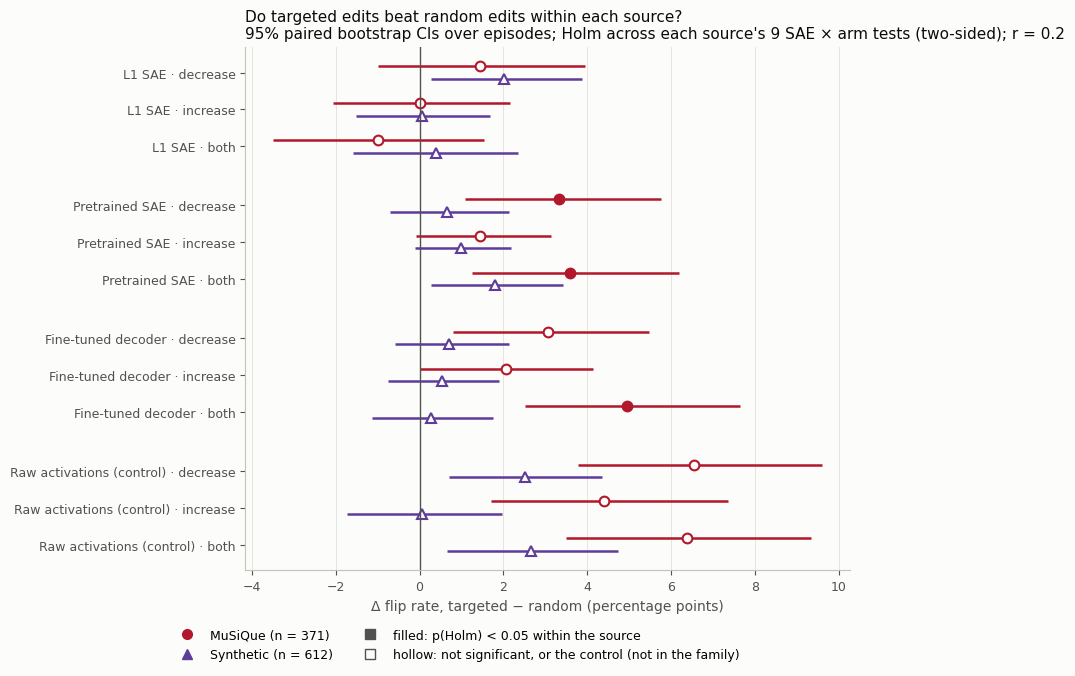

MuSiQue Δ [CI]  MuSiQue p (Holm)  \
representation     arm                                             
L1 SAE             decrease  +1.4 [-1.0, +4.0]             0.897   
                   increase  +0.0 [-2.1, +2.2]             1.000   
                   both      -1.0 [-3.5, +1.5]             0.988   
Pretrained SAE     decrease  +3.3 [+1.1, +5.8]             0.046   
                   increase  +1.4 [-0.1, +3.1]             0.410   
                   both      +3.6 [+1.3, +6.2]             0.046   
Fine-tuned decoder decrease  +3.1 [+0.8, +5.5]             0.090   
                   increase  +2.1 [+0.0, +4.1]             0.308   
                   both      +4.9 [+2.5, +7.6]             0.001   
Raw activations    decrease  +6.6 [+3.8, +9.6]               NaN   
                   increase  +4.4 [+1.7, +7.4]               NaN   
                   both      +6.4 [+3.5, +9.3]               NaN   

                              Synthetic Δ [CI]  Synthetic p (Holm)  \
representation     arm                                               
L1 SAE             decrease  +2.0 [+0.3, +3.9]               0.304   
                   increase  +0.1 [-1.5, +1.7]               1.000   
                   both      +0.4 [-1.6, +2.3]               1.000   
Pretrained SAE     decrease  +0.7 [-0.7, +2.1]               1.000   
                   increase  +1.0 [-0.1, +2.2]               0.748   
                   both      +1.8 [+0.3, +3.4]               0.304   
Fine-tuned decoder decrease  +0.7 [-0.6, +2.1]               1.000   
                   increase  +0.5 [-0.8, +1.9]               1.000   
                   both      +0.3 [-1.1, +1.7]               1.000   
Raw activations    decrease  +2.5 [+0.7, +4.4]                 NaN   
                   increase  +0.1 [-1.7, +2.0]                 NaN   
                   both      +2.7 [+0.7, +4.7]                 NaN   

                            MuSiQue − synthetic [CI]  gap p (Holm)  
representation     arm                                              
L1 SAE             decrease        -0.6 [-3.7, +2.6]         1.000  
                   increase        -0.1 [-2.7, +2.6]         1.000  
                   both            -1.4 [-4.6, +1.8]         1.000  
Pretrained SAE     decrease        +2.7 [-0.0, +5.3]         0.310  
                   increase        +0.5 [-1.5, +2.4]         1.000  
                   both            +1.8 [-1.2, +4.8]         1.000  
Fine-tuned decoder decrease        +2.3 [-0.3, +5.1]         0.533  
                   increase        +1.5 [-0.9, +4.0]         1.000  
                   both            +4.7 [+1.8, +7.7]         0.008  
Raw activations    decrease        +4.1 [+0.6, +7.6]           NaN  
                   increase        +4.3 [+1.0, +7.8]           NaN  
                   both            +3.7 [+0.2, +7.4]           NaN

In [7]:
flip_effects = effects_by_source()
flip_gaps = source_gaps()

fig, ax = plt.subplots(figsize=(7.8, 6.8))
forest_by_source(ax, flip_effects, REPRESENTATIONS, filled_column="survives_holm")
ax.set_xlabel("Δ flip rate, targeted − random (percentage points)")
ax.legend(handles=source_handles() + FILL_HANDLES, loc="upper center", bbox_to_anchor=(0.35, -0.09), ncol=2)
ax.set_title("Do targeted edits beat random edits within each source?\n"
             "95% paired bootstrap CIs over episodes; Holm across each source's 9 SAE × arm tests (two-sided); "
             f"r = {EDIT_SIZE}", loc="left")
save_figure(fig, "section1_targeted_minus_random_flip_rate_by_source")
plt.show()

display(source_table(flip_effects, flip_gaps))

**Takeaway:** on MuSiQue, 3 of 9 tests survive Holm: Pretrained "decrease" (+3.3 pp) and "both" (+3.6), and
Fine-tuned decoder "both" (+4.9). On synthetic none do. But the sources differ significantly only for Fine-tuned
decoder "both" (+4.7 pp, p(Holm) = 0.008); for the other rows they can't be told apart.

**In absolute terms:** the two flip rates that Δ subtracts, per source, on the same axis.

Saved results/intervention_layer25/20261106T000808809026Z-02871d677287/merge/figures/further_analysis/section1_absolute_flip_rates_targeted_vs_random_by_source.svg


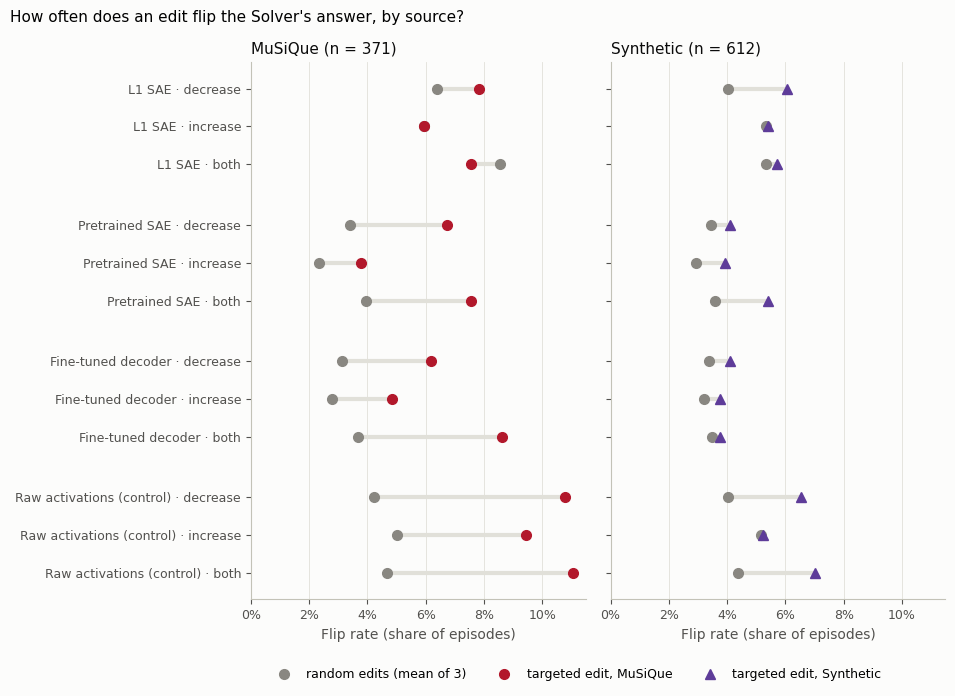

In [8]:
positions = row_positions(REPRESENTATIONS)
fig, axes = plt.subplots(1, 2, figsize=(9.6, 6.6), sharey=True, sharex=True)
for ax, source in zip(axes, SOURCES):
    rows = flip_effects[flip_effects.source == source]
    for (representation, arm), y in positions.items():
        row = rows[(rows.representation == representation) & (rows.arm == arm)].iloc[0]
        ax.plot([row.random_pct, row.targeted_pct], [y, y], color=GRID, linewidth=3, zorder=1)
        ax.plot(row.random_pct, y, marker="o", color=RANDOM_GRAY, linestyle="none", zorder=2)
        ax.plot(row.targeted_pct, y, marker=SOURCE_MARKER[source], color=SOURCE_COLOR[source], linestyle="none",
                zorder=3)
    ax.set_yticks(list(positions.values()), [f"{rep}{' (control)' if rep == RAW else ''} · {arm}" for rep, arm in positions])
    ax.set_ylim(max(positions.values()) + 0.7, -0.7)
    ax.grid(axis="y", visible=False)
    ax.set_xlim(left=0)
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
    ax.set_xlabel("Flip rate (share of episodes)")
    ax.set_title(f"{SOURCE_NAME[source]} (n = {len(episodes_by_source[source])})", loc="left")
fig.suptitle("How often does an edit flip the Solver's answer, by source?", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
fig.legend(handles=[Line2D([], [], marker="o", color=RANDOM_GRAY, linestyle="none", label="random edits (mean of 3)")]
           + [Line2D([], [], marker=SOURCE_MARKER[s], color=SOURCE_COLOR[s], linestyle="none",
                     label=f"targeted edit, {SOURCE_NAME[s]}") for s in SOURCES],
           loc="upper center", bbox_to_anchor=(0.6, 0.0), ncol=3)
save_figure(fig, "section1_absolute_flip_rates_targeted_vs_random_by_source")
plt.show()

**Takeaway:** random edits flip about the same share of answers in both sources (2.3–4.0% for Pretrained and
Fine-tuned decoder). The difference is what the targeted edit adds: up to 8.6% on MuSiQue, against at most 5.4% on
synthetic. These edits nudge the decision; they don't control it.

## 2. Do SAE features add causal value over raw activations?

For each SAE and arm: the raw control's Δ minus the SAE's Δ, paired by episode, using the pipeline's test
(two-sided) with Holm across each source's 9 comparisons. Right of zero means raw directions steer more.

Saved results/intervention_layer25/20261106T000808809026Z-02871d677287/merge/figures/further_analysis/section2_raw_activations_minus_sae_effect_by_source.svg


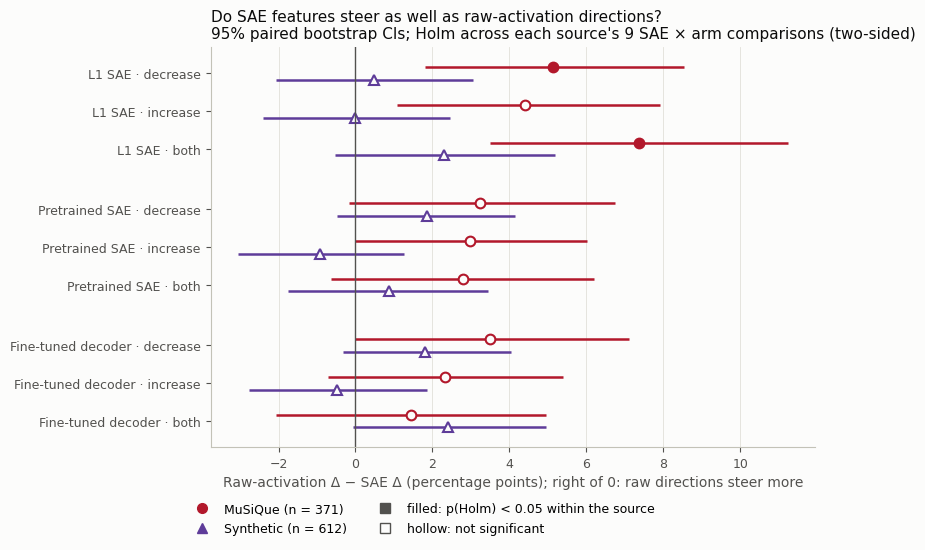

MuSiQue: raw − SAE [CI] Synthetic: raw − SAE [CI]  \
SAE                arm                                                          
L1 SAE             decrease       +5.1 [+1.8, +8.5]         +0.5 [-2.1, +3.1]   
                   increase       +4.4 [+1.1, +7.9]         +0.0 [-2.4, +2.5]   
                   both          +7.4 [+3.5, +11.2]         +2.3 [-0.5, +5.2]   
Pretrained SAE     decrease       +3.2 [-0.2, +6.7]         +1.9 [-0.5, +4.1]   
                   increase       +3.0 [+0.0, +6.0]         -0.9 [-3.1, +1.3]   
                   both           +2.8 [-0.6, +6.2]         +0.9 [-1.7, +3.4]   
Fine-tuned decoder decrease       +3.5 [+0.0, +7.1]         +1.8 [-0.3, +4.0]   
                   increase       +2.3 [-0.7, +5.4]         -0.5 [-2.8, +1.9]   
                   both           +1.4 [-2.1, +4.9]         +2.4 [-0.1, +5.0]   

                             MuSiQue: p (Holm)  Synthetic: p (Holm)  
SAE                arm                                               
L1 SAE             decrease              0.034                1.000  
                   increase              0.091                1.000  
                   both                  0.004                0.902  
Pretrained SAE     decrease              0.349                0.902  
                   increase              0.349                1.000  
                   both                  0.382                1.000  
Fine-tuned decoder decrease              0.349                0.902  
                   increase              0.382                1.000  
                   both                  0.451                0.569

Cosine between each representation's adoption and retention edit directions (recorded by the run): {'Raw activations': 0.0, 'L1 SAE': 0.75, 'Pretrained SAE': 0.13, 'Fine-tuned decoder': 0.17, 'Fully fine-tuned': 0.26}


In [9]:
raw_vs_sae_rows = []
for source in SOURCES:
    ids, rows = episodes_by_source[source], []
    for sae in PRIMARY_SAES:
        for arm in ARMS:
            result = outcomes.test(per_episode_delta(RAW, arm, ids), per_episode_delta(sae, arm, ids), "two-sided")
            rows.append({"source": source, "representation": sae, "arm": arm, "delta_pp": result["delta_pp"],
                         "ci_low_pp": result["ci95_pp"][0], "ci_high_pp": result["ci95_pp"][1],
                         "p_value": result["p_value"]})
    raw_vs_sae_rows.append(with_holm(rows, PRIMARY_SAES))
raw_vs_sae = pd.concat(raw_vs_sae_rows, ignore_index=True)

fig, ax = plt.subplots(figsize=(7.8, 5.2))
forest_by_source(ax, raw_vs_sae, PRIMARY_SAES, filled_column="survives_holm")
ax.set_xlabel("Raw-activation Δ − SAE Δ (percentage points); right of 0: raw directions steer more")
ax.legend(handles=source_handles() + FILL_HANDLES[:1]
          + [Line2D([], [], marker="s", color=INK_2, markerfacecolor=BACKGROUND, linestyle="none",
                    label="hollow: not significant")],
          loc="upper center", bbox_to_anchor=(0.35, -0.11), ncol=2)
ax.set_title("Do SAE features steer as well as raw-activation directions?\n"
             "95% paired bootstrap CIs; Holm across each source's 9 SAE × arm comparisons (two-sided)", loc="left")
save_figure(fig, "section2_raw_activations_minus_sae_effect_by_source")
plt.show()

display(pd.DataFrame({
    f"{SOURCE_NAME[source]}: raw − SAE [CI]": [ci_cell(*v) for v in
                                               raw_vs_sae[raw_vs_sae.source == source][["delta_pp", "ci_low_pp", "ci_high_pp"]].to_numpy()]
    for source in SOURCES} | {
    f"{SOURCE_NAME[source]}: p (Holm)": raw_vs_sae[raw_vs_sae.source == source].p_holm.round(3).to_numpy()
    for source in SOURCES}, index=pd.MultiIndex.from_tuples(row_positions(PRIMARY_SAES), names=["SAE", "arm"])))
print("Cosine between each representation's adoption and retention edit directions (recorded by the run):",
      {name: round(cosine, 2) for name, cosine in frozen_run["recorded"]["set_cosines"].items()})

**Takeaway:** no SAE steers more than raw activations in either source. On MuSiQue, raw beats L1 clearly (+5.1
and +7.4 pp, p(Holm) ≤ 0.034), consistent with L1's overlapping adoption and retention directions (cosine 0.75).
The Pretrained SAE and Fine-tuned decoder trail raw by 1.4–3.5 pp, which isn't significant.

## 3. Do Critic refusals explain the difference?

"No answer" is the rule-based reading of C1: a refusal such as "the paragraphs don't mention it", a premise
rejection, or unresolved text. The panels compare the sources within each group, using each episode's Δ averaged
over the SAE × arm conditions (left) or the raw control's 3 arms (right).

,MuSiQue,Synthetic
Episodes analysed (excluded),371 (4),612 (13)
Stored adoption / retention,214 / 157,282 / 330
Critic gave no answer,48.0%,12.3%
Solver unsure (baseline first-token p < 0.999),23.5%,13.9%
2 / 3 / 4 hops,244 / 96 / 31,122 / 235 / 255


Saved results/intervention_layer25/20261106T000808809026Z-02871d677287/merge/figures/further_analysis/section3_effect_by_source_and_critic_answer.svg


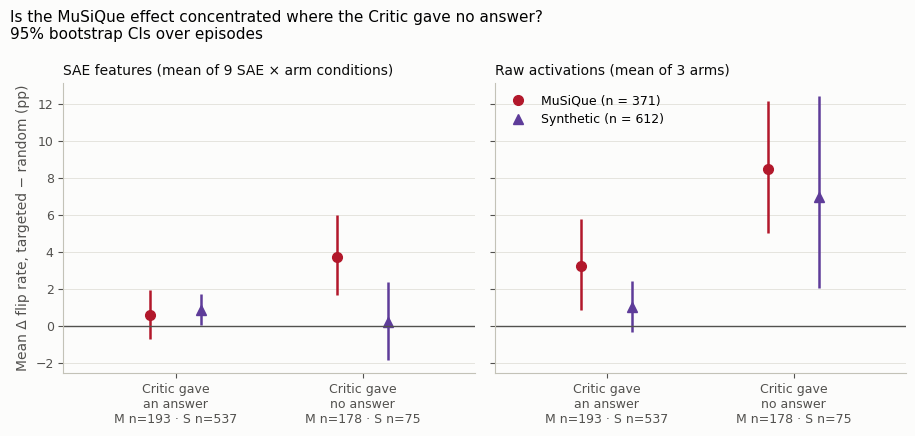

Mean Δ (pp) [95% CI] by group, with the number of episodes:


column                                                SAE: MuSiQue (n)  \
grouping                group                                            
What the Critic gave    Critic gave an answer  +0.6 [-0.7, +2.0] (193)   
                        Critic gave no answer  +3.7 [+1.7, +6.0] (178)   
The Solver's confidence unsure (p < 0.999)     +7.2 [+2.9, +11.8] (87)   
                        confident (p ≥ 0.999)  +0.5 [-0.2, +1.4] (284)   
Number of hops          2 hops                 +2.5 [+1.1, +4.2] (244)   
                        3–4 hops               +1.3 [-0.8, +3.5] (127)   

column                                              SAE: Synthetic (n)  \
grouping                group                                            
What the Critic gave    Critic gave an answer  +0.9 [+0.1, +1.8] (537)   
                        Critic gave no answer   +0.2 [-1.8, +2.4] (75)   
The Solver's confidence unsure (p < 0.999)      +3.9 [-0.7, +8.7] (85)   
                        confident (p ≥ 0.999)  +0.3 [-0.1, +0.8] (527)   
Number of hops          2 hops                 +0.5 [-1.0, +2.2] (122)   
                        3–4 hops               +0.9 [+0.0, +1.8] (490)   

column                                                 Raw: MuSiQue (n)  \
grouping                group                                             
What the Critic gave    Critic gave an answer   +3.3 [+0.9, +5.8] (193)   
                        Critic gave no answer  +8.5 [+5.1, +12.2] (178)   
The Solver's confidence unsure (p < 0.999)     +11.4 [+4.7, +18.1] (87)   
                        confident (p ≥ 0.999)   +4.1 [+2.3, +6.0] (284)   
Number of hops          2 hops                  +6.6 [+4.0, +9.3] (244)   
                        3–4 hops                +4.2 [+0.9, +7.8] (127)   

column                                              Raw: Synthetic (n)  
grouping                group                                           
What the Critic gave    Critic gave an answer  +1.0 [-0.3, +2.4] (537)  
                        Critic gave no answer  +7.0 [+2.1, +12.4] (75)  
The Solver's confidence unsure (p < 0.999)      +0.0 [-6.7, +6.8] (85)  
                        confident (p ≥ 0.999)  +2.0 [+0.9, +3.2] (527)  
Number of hops          2 hops                 +2.5 [-0.8, +5.9] (122)  
                        3–4 hops               +1.6 [+0.1, +3.1] (490)

In [10]:
excluded_by_source = pd.Series([e.split(":")[0] for e in summary["excluded_episodes"]]).value_counts()
display(pd.DataFrame({SOURCE_NAME[source]: {
    "Episodes analysed (excluded)": f"{len(facts)} ({int(excluded_by_source.get(source, 0))})",
    "Stored adoption / retention": f"{int((facts.stratum == 'adoption').sum())} / {int((facts.stratum == 'retention').sum())}",
    "Critic gave no answer": share(~facts.critic_gave_answer),
    f"Solver unsure (baseline first-token p < {CONFIDENT})": share(~facts.confident),
    "2 / 3 / 4 hops": " / ".join(str(int((facts.hops == hops).sum())) for hops in (2, 3, 4)),
} for source, facts in episode_facts.groupby("source")}))

PANELS = {  # title: per-episode Δ, averaged over the panel's conditions
    f"SAE features (mean of {len(PRIMARY_SAES) * len(ARMS)} SAE × arm conditions)":
        np.mean([per_episode_delta(rep, arm) for rep in PRIMARY_SAES for arm in ARMS], axis=0),
    f"Raw activations (mean of {len(ARMS)} arms)": np.mean([per_episode_delta(RAW, arm) for arm in ARMS], axis=0),
}
CRITIC_GROUPS = {True: "Critic gave\nan answer", False: "Critic gave\nno answer"}
GROUPINGS = {  # grouping: (episode_facts column, {value: label}); the figure shows the Critic, the table all three
    "What the Critic gave": ("critic_gave_answer", CRITIC_GROUPS),
    "The Solver's confidence": ("confident", {False: f"unsure (p < {CONFIDENT})", True: f"confident (p ≥ {CONFIDENT})"}),
    "Number of hops": ("two_hop", {True: "2 hops", False: "3–4 hops"}),
}

group_rows = []
for panel, mean_delta in PANELS.items():
    for grouping, (column, labels) in GROUPINGS.items():
        for value, label in labels.items():
            for source in SOURCES:
                mask = ((episode_facts[column] == value) & (episode_facts.source == source)).to_numpy()
                ci_low, ci_high = stats.bootstrap_ci(mean_delta[mask], analysis_plan.n_bootstrap, BOOTSTRAP_SEED)
                group_rows.append({"panel": panel, "grouping": grouping, "group": label, "source": source,
                                   "n": int(mask.sum()), "delta_pp": 100 * mean_delta[mask].mean(),
                                   "ci_low_pp": 100 * ci_low, "ci_high_pp": 100 * ci_high})
group_effects = pd.DataFrame(group_rows)

fig, axes = plt.subplots(1, len(PANELS), figsize=(4.6 * len(PANELS), 4.4), sharey=True)
for ax, panel in zip(axes, PANELS):
    tick_labels = []
    for x, label in enumerate(CRITIC_GROUPS.values()):
        counts = []
        for source in SOURCES:
            row = group_effects[(group_effects.panel == panel) & (group_effects.group == label)
                                & (group_effects.source == source)].iloc[0]
            x_source = x + SOURCE_OFFSET[source] * 0.8
            ax.plot([x_source, x_source], [row.ci_low_pp, row.ci_high_pp], color=SOURCE_COLOR[source],
                    linewidth=1.8, solid_capstyle="butt")
            ax.plot(x_source, row.delta_pp, marker=SOURCE_MARKER[source], color=SOURCE_COLOR[source],
                    linestyle="none")
            counts.append(f"{SOURCE_NAME[source][0]} n={row.n}")
        tick_labels.append(f"{label}\n{' · '.join(counts)}")
    ax.set_xticks(range(len(CRITIC_GROUPS)), tick_labels)
    ax.set_xlim(-0.6, len(CRITIC_GROUPS) - 0.4)
    ax.axhline(0, color=INK_2, linewidth=1)
    ax.grid(axis="x", visible=False)
    ax.grid(axis="y", visible=True)
    ax.set_title(panel, loc="left", fontsize=10)
axes[0].set_ylabel("Mean Δ flip rate, targeted − random (pp)")
axes[-1].legend(handles=source_handles(), loc="upper left")
fig.suptitle("Is the MuSiQue effect concentrated where the Critic gave no answer?\n"
             "95% bootstrap CIs over episodes", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
save_figure(fig, "section3_effect_by_source_and_critic_answer")
plt.show()

group_table = group_effects.assign(
    group=group_effects.group.str.replace("\n", " "),
    column=[f"{'SAE' if panel == next(iter(PANELS)) else 'Raw'}: {SOURCE_NAME[source]} (n)"
            for panel, source in zip(group_effects.panel, group_effects.source)],
    value=[f"{ci_cell(d, lo, hi)} ({int(n)})" for d, lo, hi, n in
           group_effects[["delta_pp", "ci_low_pp", "ci_high_pp", "n"]].to_numpy()])
print("Mean Δ (pp) [95% CI] by group, with the number of episodes:")
display(group_table.pivot(index=["grouping", "group"], columns="column", values="value")
        .reindex([(g, label.replace("\n", " ")) for g, (_, labels) in GROUPINGS.items() for label in labels.values()])
        [[f"{rep}: {SOURCE_NAME[s]} (n)" for rep in ("SAE", "Raw") for s in SOURCES]])

**Does matching the mix close the gap?** The synthetic episodes are reweighted to MuSiQue's mix of each property,
for both panels. If the gap falls to about zero, that property explains it. Matching all three at once would
leave cells of 2 episodes.

In [11]:
def standardized_gap(per_episode: np.ndarray, groups: pd.Series, *, n_bootstrap: int, seed: int) -> dict:
    """MuSiQue mean − synthetic mean, with the synthetic episodes reweighted to MuSiQue's mix of `groups`.
    CI: bootstrap resampling episodes within each source."""
    codes = pd.factorize(groups, sort=True)[0]
    n_groups = codes.max() + 1
    m_values, m_codes = per_episode[is_musique], codes[is_musique]
    s_values, s_codes = per_episode[~is_musique], codes[~is_musique]

    def estimate(m_values, m_codes, s_values, s_codes):
        weights = np.bincount(m_codes, minlength=n_groups) / len(m_codes)
        synthetic_means = (np.bincount(s_codes, weights=s_values, minlength=n_groups)
                           / np.bincount(s_codes, minlength=n_groups))
        return m_values.mean() - weights @ synthetic_means

    rng = np.random.default_rng(seed)
    draws = []
    for _ in range(n_bootstrap):
        m = rng.integers(0, len(m_values), len(m_values))
        s = rng.integers(0, len(s_values), len(s_values))
        draws.append(estimate(m_values[m], m_codes[m], s_values[s], s_codes[s]))
    if not np.isfinite(draws).all():
        raise ValueError("A bootstrap sample left a group without synthetic episodes; use coarser groups.")
    ci_low, ci_high = np.quantile(draws, [0.025, 0.975])
    observed = estimate(m_values, m_codes, s_values, s_codes)
    return {"gap_pp": 100 * observed, "ci_low_pp": 100 * ci_low, "ci_high_pp": 100 * ci_high}


ADJUSTMENTS = {
    "No adjustment": pd.Series("all", index=episode_facts.index),
    "Matched on what the Critic gave": episode_facts.critic_gave_answer,
    "Matched on the Solver's confidence": episode_facts.confident,
    "Matched on the number of hops (2 vs 3–4)": episode_facts.two_hop,
    "Matched on confidence and what the Critic gave":
        episode_facts.confident.astype(str) + "/" + episode_facts.critic_gave_answer.astype(str),
}
adjusted_gaps = pd.DataFrame([{"panel": panel, "comparison": name,
                               **standardized_gap(mean_delta, groups, n_bootstrap=analysis_plan.n_bootstrap,
                                                  seed=BOOTSTRAP_SEED)}
                              for panel, mean_delta in PANELS.items() for name, groups in ADJUSTMENTS.items()])
display(adjusted_gaps.assign(value=[f"{g:+.2f} [{lo:+.2f}, {hi:+.2f}]" for g, lo, hi in
                                    adjusted_gaps[["gap_pp", "ci_low_pp", "ci_high_pp"]].to_numpy()])
        .pivot(index="comparison", columns="panel", values="value").loc[list(ADJUSTMENTS), list(PANELS)]
        .rename_axis(columns="MuSiQue − synthetic, mean Δ (pp) [95% CI]"))

"MuSiQue − synthetic, mean Δ (pp) [95% CI]",SAE features (mean of 9 SAE × arm conditions),Raw activations (mean of 3 arms)
comparison,,
No adjustment,"+1.27 [-0.16, +2.79]","+4.04 [+1.54, +6.59]"
Matched on what the Critic gave,"+1.51 [-0.16, +3.24]","+1.91 [-1.53, +5.25]"
Matched on the Solver's confidence,"+0.93 [-0.76, +2.65]","+4.23 [+1.47, +7.14]"
Matched on the number of hops (2 vs 3–4),"+1.43 [-0.21, +3.12]","+3.63 [+0.46, +6.66]"
Matched on confidence and what the Critic gave,"+1.29 [-0.57, +3.27]","+1.79 [-2.04, +5.55]"


**Takeaway:** MuSiQue has four times as many Critic refusals (48% vs 12%).
- **Raw directions:** refusals explain about half the source gap (+4.0 → +1.9 pp after matching), because raw edits
  work best when the Critic refused, in both sources.
- **SAE features:** refusals don't explain the gap (+1.3 → +1.5). Their effect appears in refusal episodes only on
  MuSiQue (+3.7 vs +0.6 when the Critic answered), not on synthetic (+0.2, from 75 episodes).

In both sources the effect lives among unsure episodes (SAE: MuSiQue +7.2, synthetic +3.9; confident: +0.5,
+0.3). Confidence and hops close neither gap.

## 4. Does it hold without Claude's labels?

Two checks with no model involved.

**4a. Did the edit change the answer at all?** "Changed" means the text differs from the baseline answer. A
change isn't necessarily a flip.

In [12]:
baseline_answer = {e: outcomes.rows[(e, "baseline")]["answer"] for e in episodes}


def answer_changed(row: dict) -> bool:
    return row["answer"] != baseline_answer[row["episode_id"]]


# Changed answers are exactly the ones the pipeline sent to Claude; unchanged ones reuse the stored label.
if any(answer_changed(row) != (row["label_source"] == "claude") for row in edit_rows):
    raise AssertionError("Changed answers should be exactly the answers Claude labeled.")

print("Δ share of answers changed, targeted − random (pp):")
display(source_table(effects_by_source(answer_changed)))

Δ share of answers changed, targeted − random (pp):


MuSiQue Δ [CI]  MuSiQue p (Holm)  \
representation     arm                                                
L1 SAE             decrease     -2.4 [-5.6, +0.7]             0.552   
                   increase    -8.4 [-11.7, -5.2]             0.001   
                   both       -10.4 [-13.7, -7.1]             0.001   
Pretrained SAE     decrease     +5.1 [+1.5, +8.7]             0.034   
                   increase     +0.4 [-1.9, +2.8]             1.000   
                   both         +0.4 [-2.6, +3.5]             1.000   
Fine-tuned decoder decrease     +5.6 [+2.0, +9.3]             0.024   
                   increase     +0.4 [-2.2, +3.1]             1.000   
                   both         +3.0 [-0.1, +6.2]             0.338   
Raw activations    decrease  +25.8 [+21.0, +30.5]               NaN   
                   increase    +6.3 [+2.4, +10.3]               NaN   
                   both      +19.3 [+14.7, +24.0]               NaN   

                                 Synthetic Δ [CI]  Synthetic p (Holm)  
representation     arm                                                 
L1 SAE             decrease     -1.3 [-3.4, +0.8]               1.000  
                   increase     -1.1 [-3.3, +1.0]               1.000  
                   both        -9.6 [-12.0, -7.2]               0.001  
Pretrained SAE     decrease     +3.6 [+1.4, +5.9]               0.008  
                   increase     +0.3 [-0.9, +1.6]               1.000  
                   both         +1.6 [-0.3, +3.5]               0.686  
Fine-tuned decoder decrease     +5.2 [+2.9, +7.7]               0.002  
                   increase     -0.3 [-1.8, +1.2]               1.000  
                   both         +0.6 [-1.3, +2.5]               1.000  
Raw activations    decrease  +23.6 [+20.0, +27.2]                 NaN  
                   increase     -1.1 [-3.4, +1.3]                 NaN  
                   both      +13.8 [+10.5, +17.1]                 NaN

**4b. Rule-based flips.** The project's text rules (`behavior_labels`, `V020_CANDIDATE`) compare A2 with A1, C1
and the question's aliases. A rule flip is a stored adoption that now retains A1, or a stored retention that now
adopts C1. The rules can't read a switch to or from a refusal, so they undercount flips, most of all on MuSiQue.

In [13]:
RULE_TARGET = {"adoption": "retained_a1", "retention": "adopted_critic"}  # the rules' reading of a flip
RULE_STORED = {"adoption": "adopted_critic", "retention": "retained_a1"}  # the rules' reading of the stored label
episode_facts["rules_read_stored_label"] = [
    classify_candidate(stored_episodes[e], V020_CANDIDATE)["solver_response"] == RULE_STORED[outcomes.stratum[e]]
    for e in episodes]
rule_response = {}
for row in edit_rows:
    if answer_changed(row):
        edited = {**stored_episodes[row["episode_id"]], "solver_attempt_2": row["answer"],
                  "solver_a2_first_token_id": row["first_token_id"]}
        rule_response[(row["episode_id"], row["condition"])] = classify_candidate(edited, V020_CANDIDATE)["solver_response"]


def is_rule_flip(row: dict) -> bool:
    """The rules read the edited answer as the other side. Unchanged answers never flip."""
    return rule_response.get((row["episode_id"], row["condition"])) == RULE_TARGET[row["stored_label"]]


rule_effects, rule_gaps = effects_by_source(is_rule_flip), source_gaps(is_rule_flip)
display(source_table(rule_effects, rule_gaps))

# Robustness checks by source. "All edits" counts every changed edited answer; "SAE edits" the 9 SAE × arm conditions.
answers = pd.DataFrame([{"source": row["episode_id"].split(":")[0], "episode_id": row["episode_id"],
                         "representation": row["representation"], "edit": row["source"],
                         "changed": answer_changed(row), "flip": is_flip(row), "rule_flip": is_rule_flip(row),
                         "rule_reading": rule_response.get((row["episode_id"], row["condition"]), "unchanged"),
                         "out": row["label"] == "out"} for row in edit_rows])
checks = {}
for source in SOURCES:
    rows = answers[answers.source == source]
    sae_rows = rows[rows.representation.isin(PRIMARY_SAES)]
    targeted, random = sae_rows[sae_rows.edit == "targeted"], sae_rows[sae_rows.edit == "random"]
    flips_per_episode = targeted.groupby("episode_id").flip.sum()
    facts = episode_facts[episode_facts.source == source]
    checks[SOURCE_NAME[source]] = {
        "Rules read Claude's stored label, adoption / retention":
            " / ".join(share(facts.rules_read_stored_label[facts.stratum == stratum]) for stratum in ("adoption", "retention")),
        "Claude flips the rules confirm (all edits)":
            f"{int((rows.flip & rows.rule_flip).sum())} of {int(rows.flip.sum())} ({share(rows.rule_flip[rows.flip])})",
        "Flips only the rules find (all edits)": f"{int((rows.rule_flip & ~rows.flip).sum())} of {int(rows.changed.sum())} changed answers",
        "Answers changed, targeted / random (SAE edits)": f"{share(targeted.changed)} / {share(random.changed)}",
        "Changed answers that are flips, targeted / random (SAE edits)":
            f"{share(targeted.flip[targeted.changed])} / {share(random.flip[random.changed])}",
        "Out answers, targeted / random (SAE edits)": f"{share(targeted.out)} / {share(random.out)}",
        "Targeted flips from the 3 most-flipping episodes (SAE edits)":
            f"{100 * flips_per_episode.nlargest(3).sum() / flips_per_episode.sum():.1f}%",
    }
display(pd.DataFrame(checks))

claude_only = answers[answers.flip & ~answers.rule_flip]
print("Flips Claude found but the rules didn't (all edits): what the rules read instead")
display(pd.crosstab(claude_only.rule_reading, claude_only.source.map(SOURCE_NAME)))

MuSiQue Δ [CI]  MuSiQue p (Holm)  \
representation     arm                                             
L1 SAE             decrease  +1.8 [-0.4, +4.0]             0.588   
                   increase  -0.2 [-1.4, +1.1]             1.000   
                   both      +1.1 [-1.1, +3.3]             1.000   
Pretrained SAE     decrease  +0.6 [-1.0, +2.3]             1.000   
                   increase  +1.5 [+0.1, +3.1]             0.501   
                   both      +2.0 [+0.0, +4.1]             0.501   
Fine-tuned decoder decrease  +1.0 [-0.8, +3.0]             1.000   
                   increase  +1.8 [+0.0, +3.7]             0.501   
                   both      +3.8 [+1.7, +6.0]             0.005   
Raw activations    decrease  +4.0 [+1.7, +6.5]               NaN   
                   increase  +3.1 [+0.8, +5.4]               NaN   
                   both      +4.0 [+1.7, +6.4]               NaN   

                              Synthetic Δ [CI]  Synthetic p (Holm)  \
representation     arm                                               
L1 SAE             decrease  +1.4 [-0.2, +3.0]               0.807   
                   increase  -0.4 [-1.7, +1.0]               1.000   
                   both      +1.1 [-0.7, +3.0]               1.000   
Pretrained SAE     decrease  +0.6 [-0.7, +2.0]               1.000   
                   increase  +1.3 [+0.2, +2.4]               0.238   
                   both      +1.9 [+0.3, +3.4]               0.222   
Fine-tuned decoder decrease  +0.9 [-0.4, +2.2]               1.000   
                   increase  +0.5 [-0.7, +1.9]               1.000   
                   both      +0.2 [-1.1, +1.7]               1.000   
Raw activations    decrease  +0.5 [-0.8, +2.0]                 NaN   
                   increase  +0.8 [-0.8, +2.4]                 NaN   
                   both      +1.9 [+0.2, +3.8]                 NaN   

                            MuSiQue − synthetic [CI]  gap p (Holm)  
representation     arm                                              
L1 SAE             decrease        +0.4 [-2.2, +3.2]         1.000  
                   increase        +0.2 [-1.7, +2.2]         1.000  
                   both            -0.1 [-2.9, +2.8]         1.000  
Pretrained SAE     decrease        +0.0 [-2.1, +2.1]         1.000  
                   increase        +0.3 [-1.6, +2.2]         1.000  
                   both            +0.1 [-2.5, +2.7]         1.000  
Fine-tuned decoder decrease        +0.1 [-2.2, +2.4]         1.000  
                   increase        +1.3 [-0.9, +3.5]         1.000  
                   both            +3.6 [+1.1, +6.2]         0.039  
Raw activations    decrease        +3.5 [+0.8, +6.3]           NaN  
                   increase        +2.3 [-0.5, +5.2]           NaN  
                   both            +2.0 [-0.8, +5.0]           NaN

,MuSiQue,Synthetic
"Rules read Claude's stored label, adoption / retention",41.1% / 79.6%,77.3% / 92.4%
Claude flips the rules confirm (all edits),686 of 1107 (62.0%),1327 of 1560 (85.1%)
Flips only the rules find (all edits),14 of 2709 changed answers,3 of 2992 changed answers
"Answers changed, targeted / random (SAE edits)",11.5% / 12.2%,7.6% / 7.7%
"Changed answers that are flips, targeted / random (SAE edits)",57.0% / 36.5%,62.0% / 50.4%
"Out answers, targeted / random (SAE edits)",1.3% / 1.5%,1.1% / 1.6%
Targeted flips from the 3 most-flipping episodes (SAE edits),11.4%,9.7%


Flips Claude found but the rules didn't (all edits): what the rules read instead


source,MuSiQue,Synthetic
rule_reading,,
non_answer,185,56
produced_answer,89,27
third_answer,8,49
unchanged_same_position,0,36
unresolved,139,65


**Takeaway:**
- **Answers changed (4a):** targeted "decrease" edits of the Pretrained SAE and Fine-tuned decoder change 3.6–5.6
  points more answers than random in both sources. MuSiQue answers change more under any edit (12% vs 8%), but
  more of the targeted changes are flips (57% against 37% for random; synthetic 62% against 50%).
- **Rule-based flips (4b):** the Fine-tuned decoder "both" result stands: +3.8 pp on MuSiQue (p(Holm) = 0.005), with
  a source gap of +3.6 (p(Holm) = 0.039). The rules almost never add flips (17 of 5,701) and confirm 62% of
  Claude's MuSiQue flips and 85% of synthetic ones. Most unconfirmed MuSiQue flips are refusals or unresolved text
  (324 of 421), which is why the Pretrained SAE's MuSiQue effect shrinks here (+3.3 → +0.6).

Out answers and flip concentration are similar in both sources.

## 5. What we can and can't say

In [14]:
def survivors(effects: pd.DataFrame, column: str = "survives_holm", source: str | None = None, sign: int = 0) -> str:
    rows = effects[effects[column] & ((effects.source == source) if source else True)]
    if sign:
        rows = rows[np.sign(rows.delta_pp) == sign]
    return ", ".join(f"{row.representation} {row.arm}" for row in rows.itertuples()) or "none"


SAE_PANEL, RAW_PANEL = PANELS


def adjusted(panel: str, name: str) -> str:
    row = adjusted_gaps.set_index(["panel", "comparison"]).loc[(panel, name)]
    return f"{row.gap_pp:+.2f} pp [{row.ci_low_pp:+.2f}, {row.ci_high_pp:+.2f}]"


sae_panel = group_effects[group_effects.panel == SAE_PANEL].set_index(["source", "group"])
claims = pd.DataFrame([
    ("1. Targeted beats random on MuSiQue (Holm within source)", survivors(flip_effects, source="musique")),
    ("1. Targeted beats random on synthetic (Holm within source)", survivors(flip_effects, source="synthetic")),
    ("1. The sources differ (Holm across 9)", survivors(flip_gaps, "gap_survives_holm")),
    ("2. An SAE steers more than raw activations (Holm within source)", survivors(raw_vs_sae, sign=-1)),
    ("2. Raw activations steer more than an SAE (Holm within source)", survivors(raw_vs_sae, sign=+1)),
    ("3. MuSiQue SAE Δ: Critic gave no answer vs an answer",
     " vs ".join(f"{sae_panel.loc[('musique', group)].delta_pp:+.1f} pp" for group in reversed(CRITIC_GROUPS.values()))),
    ("3. MuSiQue − synthetic SAE Δ, unadjusted → matched on the Critic",
     f"{adjusted(SAE_PANEL, 'No adjustment')} → {adjusted(SAE_PANEL, 'Matched on what the Critic gave')}"),
    ("3. MuSiQue − synthetic raw Δ, unadjusted → matched on the Critic",
     f"{adjusted(RAW_PANEL, 'No adjustment')} → {adjusted(RAW_PANEL, 'Matched on what the Critic gave')}"),
    ("4. Targeted beats random on MuSiQue, rule-based flips (no Claude)", survivors(rule_effects, source="musique")),
    ("4. The sources differ, rule-based flips", survivors(rule_gaps, "gap_survives_holm")),
], columns=["Claim (exploratory)", "Result in this run"])
display(claims.set_index("Claim (exploratory)"))

# Provenance: every input file, hashed before it was read, must be unchanged now that the figures are written.
changed = [name for name, path in INPUT_FILES.items() if sha256_file(path) != input_hashes[name]]
if changed:
    raise RuntimeError(f"Inputs changed while the notebook ran: {changed}")
display(pd.DataFrame({"file": {name: str(path) for name, path in INPUT_FILES.items()},
                      "sha256": input_hashes}).rename_axis("input (unchanged during the run)"))

,Result in this run
Claim (exploratory),
1. Targeted beats random on MuSiQue (Holm within source),"Pretrained SAE decrease, Pretrained SAE both, ..."
1. Targeted beats random on synthetic (Holm within source),none
1. The sources differ (Holm across 9),Fine-tuned decoder both
2. An SAE steers more than raw activations (Holm within source),none
2. Raw activations steer more than an SAE (Holm within source),"L1 SAE decrease, L1 SAE both"
3. MuSiQue SAE Δ: Critic gave no answer vs an answer,+3.7 pp vs +0.6 pp
"3. MuSiQue − synthetic SAE Δ, unadjusted → matched on the Critic","+1.27 pp [-0.16, +2.79] → +1.51 pp [-0.16, +3.24]"
"3. MuSiQue − synthetic raw Δ, unadjusted → matched on the Critic","+4.04 pp [+1.54, +6.59] → +1.91 pp [-1.53, +5.25]"
"4. Targeted beats random on MuSiQue, rule-based flips (no Claude)",Fine-tuned decoder both


,file,sha256
input (unchanged during the run),,
summary,results/intervention_layer25/20261106T00080880...,6f281fdf594aaa984c17d09125130c0a4f66a7415a8711...
frozen run,results/intervention_layer25/20261106T00080880...,1f08bfd19af8379ac5d06b92329b338c7f00ef9d047d5c...
labeled rows,results/intervention_layer25/20261106T00080880...,3a91e55bfe338df6da6419f9feaf9a484644402235af27...
Table P,results/intervention_layer25/20261106T00080880...,fd229c0d17ca99f64199ca397177aa6207999d82d81f7f...
labeling settings,results/claude_validation/mixed_final_001/inte...,3c2ce4ffbbcfcb2e471e7064c098bec548390085659a00...
stored episodes,artifacts/collection/mixed_final_001/prepared/...,dfc4bb5049979cce2cf1f8bb627004cda750a16c706b0e...


**In one sentence:** targeted SAE edits beat random on MuSiQue but not on synthetic questions, yet the sources
differ significantly only for the Fine-tuned decoder's "both" edit. Raw directions steer at least as well as any
SAE, and Critic refusals explain much of the raw gap but not the SAE gap.

**Limits**
- **Post hoc:** confirm on unused episodes with a plan fixed in advance.
- **Groups:** coarse and overlapping, with small cells (75 synthetic refusal episodes).
- **Rules:** rule-based flips undercount refusal switches.
- **Holm:** applied within each family, not across the notebook.

**Next:** add section 1's table to the paper (Review #7), and read the Fine-tuned decoder "both" MuSiQue flips by
hand.